# 10 比较KNN 与线性 SVM
## 两种完全相反的学习哲学
| 维度 | KNN | 线性 SVM |
| --- | --- | --- |
| 学习类型 | 惰性学习（lazy） | 积极学习（eager） |
| 训练阶段做什么 | 只存数据，建索引 | 解二次规划，求出 `w`、`b` |
| 模型本体 | 整个训练集 | 少量支持向量 + 权重 |
| 预测时做什么 | 和所有训练样本算距离、排序、投票 | 一次内积 `w^T x + b` |
| 模型复杂度由谁决定 | 样本数量、K、维度 | 支持向量数量 |
| 假设空间 | 任意形状（分段） | 只能线性 |

一句话对比：

- KNN 把“记忆”当成模型：**记住所有例子，临场找最像的**；
- SVM 把“边界”当成模型：**只记住几条关键向量，压缩成一个线性函数**。

##  数学形式对比
### KNN 的预测

对查询点 `x`，找最近的 K 个邻居集合 `N_K(x)`，分类时多数投票：

$$
\\hat{y}(x) = \\arg\\max\_{c}\\ \\sum\_{i \\in N\_{K}(x)} \\mathbf{1}\\left[y_i = c\\right]
$$

回归时取均值：

$$
\\hat{y}(x) = \\frac{1}{K}\\sum\_{i \\in N\_{K}(x)} y_i
$$

这里没有任何需要学习的参数，`x_i`、`y_i` 全部原样保留。

### SVM 的预测

$$
f(x) = w^{T}x + b
$$

$$
w = \\sum\_{i=1}^{n}\\alpha_i y_i x_i
$$

训练结束后，训练集可以完全丢掉，只保留 `w`、`b`（以及为算 `α` 需要的支持向量）。

**结构差异一句话**：KNN 的预测复杂度随样本量线性增长；SVM 的预测复杂度只与特征维度和支持向量数量有关，与总样本量基本脱钩（`w` 已经把信息压缩完了）。

## 决策边界的形态差异
- **线性 SVM**：全局一条直线（高维是超平面）。它必须对整片空间给出同一个朝向，无法“这块这么分、那块那么分”。
- **KNN**：边界由局部邻居决定，天然是分段折线。`K=1` 时边界碎得像 Voronoi 图，`K` 增大逐渐平滑，但永远不会变成一条全局直线。
- **RBF SVM**：介于两者之间，可以弯曲，但弯曲程度受 `γ` 控制。

这解释了一个常见现象：在月牙形、螺旋形数据上，线性 SVM 的上限被假设空间锁死，而 KNN 可以贴近真实边界。

##  复杂度与实测耗时
| 项目 | KNN | 线性 SVM |
| --- | --- | --- |
| 训练复杂度 | `O(1)` 存储（建索引另算） | 约 `O(n^2 d)` ~ `O(n^3)` |
| 预测复杂度 | `O(n d)` 每个样本 | `O(d × n_SV)` |
| 内存 | 需要保存全部训练集 | 只保存支持向量与权重 |
| 增量学习 | 直接加样本即可 | 需重新训练 |
| 高维表现 | 距离失效（维度灾难） | 相对稳定 |

实测（`d=8`，训练集 2400、测试集 600，取 7 次中位数）：

```
SVM  fit=0.00124s  predict=0.00014s
KNN  fit=0.00168s  predict=0.00578s
```

注意：这个规模下两者训练都只要毫秒级，`SVC` 的优势还没体现；差异主要在预测——KNN 慢约 41 倍。

预测耗时随训练集规模的变化（`d=8`，测试集为训练集的 1/4）：

| 训练样本数 | SVM 预测 | KNN 预测 | 倍数 |
| --- | --- | --- | --- |
| 500 | 0.00013s | 0.00149s | 12x |
| 1000 | 0.00013s | 0.00211s | 16x |
| 2000 | 0.00016s | 0.00363s | 22x |
| 4000 | 0.00031s | 0.00840s | 27x |

（多次运行的倍数大致落在 11~12x / 14~16x / 21~22x / 27~33x，绝对耗时随机器浮动，但“KNN 随样本量线性变慢、SVM 基本持平”这个趋势稳定。）

KNN 的预测时间随 `n` 近似线性增长，SVM 几乎不变（只随支持向量数微增）。**这就是在线服务几乎不会选 KNN 的原因**：用户量一上来，延迟就顶不住。

## 三组数据的实测对比
单看一组数据很容易得出片面结论，这里用三组结构不同的数据。

### 数据一：有重叠的线性数据

`make_blobs(n=300, centers=[[0,0],[2.2,2.2]], cluster_std=1.3)`

| 模型 | 测试准确率 |
| --- | --- |
| KNN（k=1） | 0.8533 |
| KNN（k=5） | 0.8267 |
| KNN（k=9） | 0.8800 |
| KNN（k=15） | 0.8400 |
| 线性 SVM（C=1） | 0.8667 |

5 折交叉验证（训练集内）：

| 模型 | CV 准确率 |
| --- | --- |
| KNN（k=1） | 0.7956 |
| KNN（k=5） | 0.8756 |
| KNN（k=15） | 0.8889 |
| 线性 SVM（C=0.1） | 0.8933 |
| 线性 SVM（C=1） | 0.8933 |
| 线性 SVM（C=10） | 0.8844 |

读法：单次划分上 KNN(k=9) 以 1.3 个点领先，但 CV 上线性 SVM 反超 0.44 个点。**两者差距很小，谁赢取决于 K 和随机划分**。这类“边界大致是直的、但噪声不小”的数据，两者都属于可接受方案。

### 数据二：明显非线性

`make_moons(n=400, noise=0.1)`

| 模型 | 测试准确率 |
| --- | --- |
| KNN（k=5） | 1.0000 |
| KNN（k=15） | 1.0000 |
| 线性 SVM（C=1） | 0.9400 |
| 线性 SVM（C=100） | 0.9400 |
| RBF SVM（C=1） | 1.0000 |

读法：KNN 领先 6 个百分点，且加大 `C` 完全救不了线性 SVM。这不是调参能解决的问题，是模型族不匹配。

### 数据三：高维

`make_classification(n=600, n_features=50, n_informative=10, n_redundant=5)`

| 模型 | 测试准确率 |
| --- | --- |
| KNN（k=5） | 0.8400 |
| KNN（k=15） | 0.9067 |
| 线性 SVM（C=1） | 0.8733 |
| 线性 SVM（C=0.1） | 0.8800 |

读法：`k=5` 的 KNN 明显掉到 0.84（高维下小 K 极不稳定，距离区分度下降），把 `k` 抬到 15 后回到 0.9067，反而超过线性 SVM。**所以“高维就该用 SVM”也不能一刀切**——KNN 在高维的问题是“k 太小”，不是“完全不可用”。

In [1]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(
    n_samples=600,
    n_features=50,
    n_informative=10,
    n_redundant=5,
    n_classes=2,
    random_state=3
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("=== 数据三：高维 d=50 ===")
for k in [5, 15]:
    knn = KNeighborsClassifier(k).fit(X_train_s, y_train)
    print("  KNN(k=%2d) acc=%.4f" % (k, knn.score(X_test_s, y_test)))

for C in [0.1, 1.0]:
    svm = SVC(kernel="linear", C=C).fit(X_train_s, y_train)
    print("  线性SVM(C=%-4g) acc=%.4f" % (C, svm.score(X_test_s, y_test)))

=== 数据三：高维 d=50 ===
  KNN(k= 5) acc=0.8400
  KNN(k=15) acc=0.9067
  线性SVM(C=0.1 ) acc=0.8800
  线性SVM(C=1   ) acc=0.8733


### 三组数据的结论汇总（带适用边界）

| 数据形态 | 谁更优 | 原因 |
| --- | --- | --- |
| 近线性、噪声中等 | 差别很小，SVM 略稳 | 边界本就是直的，SVM 假设正好匹配；KNN 受局部噪声影响 |
| 明显非线性、低维 | KNN 或 RBF-SVM 明显更优 | 线性 SVM 的假设空间不包含真实边界 |
| 高维 | 线性 SVM 稳；KNN 需调大 k | 高维距离集中，小 k 不稳；大 k 可缓解 |
| 大数据 + 低延迟 | 线性 SVM | KNN 预测线性增长 |

> 方法论提醒：任何“A 全面优于 B”的说法，在机器学习里几乎都站不住。上面的差异都能复现，但换一份数据就可能反过来。**选型必须在自己任务的数据上实测**。

=== 数据一：重叠线性 ===
  KNN(k= 1) acc=0.8533
  KNN(k= 5) acc=0.8267
  KNN(k= 9) acc=0.8800
  KNN(k=15) acc=0.8400
  线性SVM(C=1) acc=0.8667
  5折CV：
    KNN(k=5)       0.8756
    KNN(k=15)      0.8889
    线性SVM(C=1)     0.8933

=== 数据二：非线性 moons ===
  KNN(k=5)         acc=1.0000
  KNN(k=15)        acc=1.0000
  线性SVM(C=1)       acc=0.9400
  线性SVM(C=100)     acc=0.9400
  RBF-SVM(C=1)     acc=1.0000


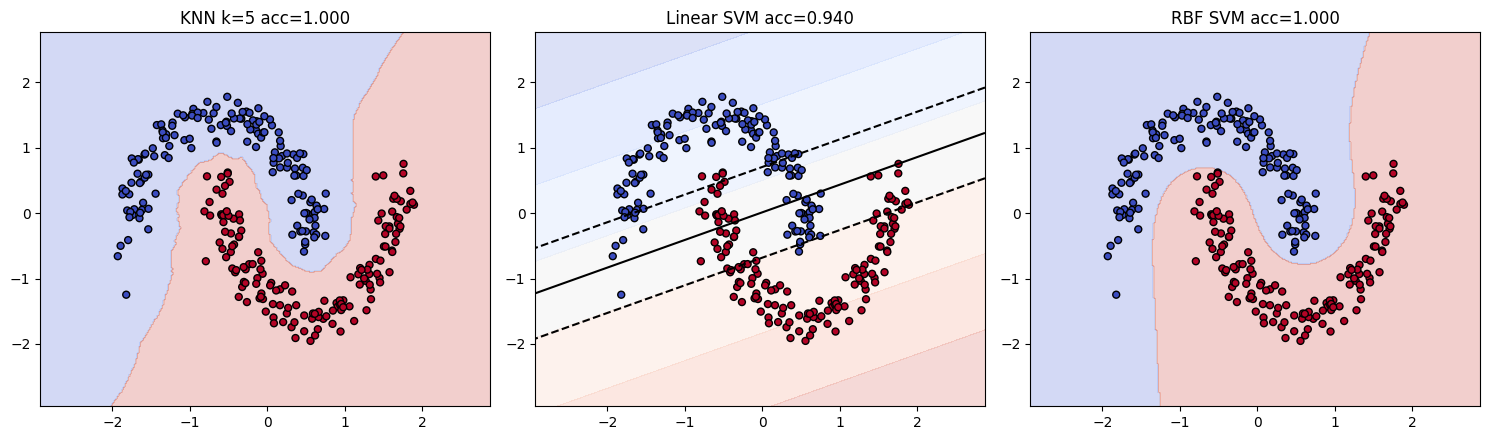

In [2]:
#  完整对比代码（三组数据 + 边界可视化）
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

# ================= 数据一：重叠线性 =================
Xb, yb = make_blobs(n_samples=300, n_features=2,
                    centers=[[0, 0], [2.2, 2.2]],
                    cluster_std=1.3, random_state=7)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xb, yb, test_size=0.25, random_state=42, stratify=yb
)
sc1 = StandardScaler()
Xb_tr_s = sc1.fit_transform(Xb_tr)
Xb_te_s = sc1.transform(Xb_te)

print("=== 数据一：重叠线性 ===")
for k in [1, 5, 9, 15]:
    knn = KNeighborsClassifier(k).fit(Xb_tr_s, yb_tr)
    print("  KNN(k=%2d) acc=%.4f" % (k, knn.score(Xb_te_s, yb_te)))
svm_lin = SVC(kernel="linear", C=1.0).fit(Xb_tr_s, yb_tr)
print("  线性SVM(C=1) acc=%.4f" % svm_lin.score(Xb_te_s, yb_te))

print("  5折CV：")
for name, model in {
    "KNN(k=5)": KNeighborsClassifier(5),
    "KNN(k=15)": KNeighborsClassifier(15),
    "线性SVM(C=1)": SVC(kernel="linear", C=1.0),
}.items():
    print("    %-14s %.4f" % (
        name, cross_val_score(model, Xb_tr_s, yb_tr, cv=5).mean()
    ))

# ================= 数据二：非线性 =================
Xm, ym = make_moons(n_samples=400, noise=0.1, random_state=42)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    Xm, ym, test_size=0.25, random_state=42, stratify=ym
)
sc2 = StandardScaler()
Xm_tr_s = sc2.fit_transform(Xm_tr)
Xm_te_s = sc2.transform(Xm_te)

print("\n=== 数据二：非线性 moons ===")
models = {
    "KNN(k=5)": KNeighborsClassifier(5),
    "KNN(k=15)": KNeighborsClassifier(15),
    "线性SVM(C=1)": SVC(kernel="linear", C=1.0),
    "线性SVM(C=100)": SVC(kernel="linear", C=100.0),
    "RBF-SVM(C=1)": SVC(kernel="rbf", C=1.0),
}
fitted = {}
for name, model in models.items():
    model.fit(Xm_tr_s, ym_tr)
    fitted[name] = model
    print("  %-16s acc=%.4f" % (name, model.score(Xm_te_s, ym_te)))

# ================= 决策边界三联图 =================
def plot_boundary(ax, X, y, model, title, use_decision=False):
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]

    if use_decision:
        Z = model.decision_function(grid).reshape(xx.shape)
        ax.contourf(xx, yy, Z, levels=np.linspace(Z.min(), Z.max(), 8),
                    alpha=0.2, cmap="coolwarm")
        ax.contour(xx, yy, Z, levels=[-1, 0, 1],
                   colors="k", linestyles=["--", "-", "--"])
    else:
        Z = model.predict(grid).reshape(xx.shape)
        ax.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")

    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=25, edgecolor="k")
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_boundary(axes[0], Xm_tr_s, ym_tr, fitted["KNN(k=5)"],
              "KNN k=5 acc=%.3f" % fitted["KNN(k=5)"].score(Xm_te_s, ym_te))
plot_boundary(axes[1], Xm_tr_s, ym_tr, fitted["线性SVM(C=1)"],
              "Linear SVM acc=%.3f" % fitted["线性SVM(C=1)"].score(Xm_te_s, ym_te),
              use_decision=True)
plot_boundary(axes[2], Xm_tr_s, ym_tr, fitted["RBF-SVM(C=1)"],
              "RBF SVM acc=%.3f" % fitted["RBF-SVM(C=1)"].score(Xm_te_s, ym_te))
plt.tight_layout()
plt.show()

## 选型清单
**选线性 SVM 的信号**

- 特征维度较高（几十到上万），样本量中等；
- 你相信类别之间大致是一条线性边界；
- 要求低延迟在线预测，且模型要小；
- 需要明确的间隔概念（例如“置信度不足就转人工”）；
- 样本量几万以内，还能接受 libsvm 的训练时间。

**选 KNN 的信号**

- 样本量不大（几百到几万），维度低（十几维以内）；
- 决策边界明显不规则，且不想调太多参数；
- 需要一个几乎零训练成本的基线；
- 多分类且类别数多（KNN 天然支持，不用训练 K 个分类器）；
- 需要“找出相似样本”这类可解释输出（推荐召回、相似商品）。

**两个都不适合的信号**

- 需要输出校准良好的概率 → 逻辑回归、梯度提升树；
- 特征里有大量类别变量、缺失值 → 树模型；
- 样本量百万级且要求实时 → 线性模型 + 特征工程，或树模型；
- 图像、文本原始输入 → 深度学习。

## 高频面试问答

**问：KNN 为什么是惰性学习？**
答：训练阶段不估计任何参数，只保存训练集（可能加索引）。所有计算推迟到预测时，用距离找邻居投票。

**问：SVM 为什么只由支持向量决定？**
答：对偶形式中 `w = Σ α_i y_i x_i`，KKT 条件保证非支持向量的 `α_i = 0`，所以它们对 `w` 没有任何贡献。

**问：SVM 的 `C` 和逻辑回归的 `C` 一样吗？**
答：不一样。SVM 的 `C` 是松弛变量惩罚（越大越严格，间隔越窄）；逻辑回归的 `C` 是正则强度倒数（越大正则越弱）。

**问：为什么 SVM 要标准化，KNN 也要？**
答：两者都基于距离/间隔的几何量。SVM 里尺度会改变同一个 `C` 的实际正则强度（实测 `||w||` 从 1.641 变到 2.385）；KNN 里尺度大的一维会直接支配距离（实测准确率从 0.9083 掉到 0.8083，见 Day7 笔记）。

**问：线性 SVM 和逻辑回归怎么选？**
答：要概率、要评分排序选逻辑回归；要最大间隔、要稀疏解、只关心分类边界选 SVM。两者准确率往往接近。

**问：SVM 怎么做多分类？**
答：`SVC` 默认 one-vs-one，K 个类训练 `K(K-1)/2` 个二分类器，投票决策；也可以 `decision_function_shape="ovr"` 把输出整理成 OvR 形状，但内部仍是 OvO。

**问：核技巧为什么能避免高维计算？**
答：对偶形式和预测式里样本只以 `x_i^T x_j` 出现，用 `K(x_i, x_j)` 直接给出高维内积结果，不需要显式计算 `φ(x)`。

**问：`decision_function` 能当概率用吗？**
答：不能。它是带符号的距离，实测范围可到 `[-3.866, 3.970]`。要概率需 `probability=True`（内部做 Platt 校准和交叉验证，训练明显变慢）。

***

## 公式速查
超平面：

$$
w^{T}x + b = 0
$$

点到超平面距离：

$$
d = \\frac{|w^{T}x + b|}{|w|}
$$

几何间隔：

$$
\\gamma_i = \\frac{y_i\\left(w^{T}x_i + b\\right)}{|w|}
$$

硬间隔目标：

$$
\\min\_{w,b}\\ \\frac{1}{2}|w|^{2}
$$

约束：

$$
y_i\\left(w^{T}x_i + b\\right) \\ge 1
$$

间隔宽度：

$$
\\text{margin} = \\frac{2}{|w|}
$$

软间隔目标：

$$
\\min\_{w,b,\\xi}\\ \\frac{1}{2}|w|^{2} + C\\sum\_{i=1}^{n}\\xi_i
$$

hinge 等价形式：

$$
\\min\_{w,b}\\ \\frac{1}{2}|w|^{2} + C\\sum\_{i=1}^{n}\\max\\left(0,\\ 1 - y_i f(x_i)\\right)
$$

对偶约束：

$$
\\alpha_i \\ge 0,\\quad \\sum\_{i=1}^{n}\\alpha_i y_i = 0
$$

权重展开：

$$
w = \\sum\_{i=1}^{n}\\alpha_i y_i x_i
$$

预测：

$$
f(x) = w^{T}x + b
$$

RBF 核：

$$
K(x, z) = \\exp\\left(-\\gamma|x - z|^{2}\\right)
$$

KNN 分类：

$$
\\hat{y}(x) = \\arg\\max\_{c}\\ \\sum\_{i \\in N\_{K}(x)} \\mathbf{1}\\left[y_i = c\\right]
$$

## 关键数字速记
| 指标 | 实测值 | 说明 |
| --- | --- | --- |
| 支持向量占比 | 68 / 225 | 只保留这些点，预测 100% 一致 |
| 支持向量重建差异 | 4.8e-4 | decision_function 最大差 |
| C=0.01 的支持向量数 | 152 | 接近“全部样本都是 SV” |
| C=1 的间隔宽度 | 0.980 | 标准化空间下 |
| moons 线性 vs KNN | 0.94 vs 1.00 | 非线性数据差 6 个点 |
| moons 线性 C=1 vs C=100 | 0.94 vs 0.94 | 调 C 救不了模型族错误 |
| KNN/SVM 预测耗时（n=4000） | 约 30x | KNN 明显更慢，且随 n 增大 |
| 尺度变化对 SVM 的影响 |  |  |

## 自检清单
☐ 能说明为什么要在所有可分超平面里选“间隔最大”的那一个

☐ 能写出点到超平面距离公式，并解释 `||w||` 的作用

☐ 能区分函数间隔与几何间隔，说清为什么要规范化到 1

☐ 能推导间隔宽度等于 `2/||w||`

☐ 能解释支持向量的定义，并用 KKT 条件说明为什么非支持向量 `α = 0`

☐ 能写出对偶问题，并指出“只出现内积”是核技巧的入口

☐ 能写出软间隔目标与 hinge loss 的等价形式

☐ 能说清 SVM 的 `C` 与逻辑回归的 `C` 在调参方向上的相反性

☐ 能解释为什么 moons 数据上调 `C` 无效、换 RBF 核立刻有效

☐ 能对比 KNN 与线性 SVM 的训练/预测复杂度，并说出 KNN 预测随 n 线性增长

☐ 能针对“近线性 / 明显非线性 / 高维 / 大数据低延迟”四类场景给出选型理由

☐ 知道 `decision_function` 不是概率，以及如何获得概率